# Octant test: α, Σ and w in each subbox

**What it does.** Splits the MultiDark box (side $L$) into $n_{\rm sub}=n_{\rm side}^3$ cubic subboxes of side
$L_{\rm sub}=L/n_{\rm side}$ (`n_side` = 2: the 8 octants, 500 h⁻¹Mpc each), and drops the galaxies within `face_guard` of the box faces
(section 1). In every subbox it measures the monopole
ξ₀(s) of the samples in `oct_samples` (Full, Q1 and the random dilution of Full with Q1's N, by default) and fits
each one as `desilike_fits.ipynb` does: α (α fit, Gaussian Σ prior), Σ (Σ fit, flat prior) and the template-free
peak width $w$ (Gaussian peak fit), each with its 68% interval. The full box is fitted the same way. The results
are listed (section 5) and drawn (section 6); there are no tests.

**Inputs:** the galaxy catalogue (`data/raw`), the run's spectra file (quartile boundaries, dilution seed, spectra
for the covariance) and the full-box monopoles (`data/processed/monopoles/box`). **Written to disk:** the subbox
monopoles (`data/processed/monopoles/subboxes`, reused unless `force_paircounts`), the subbox spectra
(`data/processed/pk/subboxes`, with `independent`; reused unless `force_spectra`) and the figures
(`figures/octant_test/<run>/`).

In [1]:
import os, re, sys, time, warnings, multiprocessing, inspect
import numpy as np
from scipy.special import erf
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

REPO = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))   # notebook lives in notebooks/exploratory
sys.path.insert(0, os.path.join(REPO, 'src'))
import bao_fitting as bf
from multidark_data_loader import load_catalog, select_sample, compute_knn_distance, split_by_variable
from multidark_correlation import get_save_filename, compute_monopole_from_xi_s_mu
from multidark_power import measure_spectra
from Corrfunc.theory.DDsmu import DDsmu
import desilike
from cosmoprimo.fiducial import Cosmology
from desilike.theories.galaxy_clustering import (BAOPowerSpectrumTemplate,
                                                 DampedBAOWigglesTracerCorrelationFunctionMultipoles)
from desilike.observables.galaxy_clustering import TracerCorrelationFunctionMultipolesObservable
from desilike.likelihoods import ObservablesGaussianLikelihood
from desilike.profilers import MinuitProfiler

# desilike's TaskManager leaks one MPI communicator per call (see desilike_fits.ipynb); free it as well. Patched
# once per kernel: re-running this cell must not wrap the patch in itself (that recursed without end)
from desilike import utils as _desilike_utils
if not getattr(_desilike_utils.TaskManager.__exit__, '_frees_rootcomm', False):
    _tm_exit = _desilike_utils.TaskManager.__exit__
    def _tm_exit_free_both(self, *exc):
        _tm_exit(self, *exc)
        rootcomm = getattr(self, 'rootcomm', None)
        if hasattr(rootcomm, 'Free'):
            rootcomm.Free()
    _tm_exit_free_both._frees_rootcomm = True
    _desilike_utils.TaskManager.__exit__ = _tm_exit_free_both

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25, 'lines.linewidth': 1.6})

# ---------------- settings (change here only) ----------------
mag = -20.8                         # absolute-magnitude cut of the run
binsep = 5.0                        # bin width of the monopoles [h^-1 Mpc]
mono_sep = (5.0, 200.0)             # separation range of the monopoles [h^-1 Mpc] (as the box files)
split_name = 'dist_fil_Q4'          # the quartile run (end of its run name in multidark_analysis.py)
oct_samples = ['Full', 'Q1', 'Full dil nQ']   # samples measured in the subboxes: 'Full', 'Q<i>', 'Full dil nQ'
n_side = 2                          # subboxes per side: n_side^3 cubes of side L / n_side (2: the 8 octants)
face_guard = 40.                    # [h^-1 Mpc] galaxies closer than this to a face of the box are dropped from the
                                    # subboxes (d_fil has an artifact there: Q1 is overrepresented within ~30 of the
                                    # faces, 2026-11-27); 0: no guard
fit_range = (50., 150.)             # [h^-1 Mpc]
peak_mu_range = (85., 125.)         # [h^-1 Mpc] Gaussian peak fit: range of its centre mu,
peak_w_range = None                 # [h^-1 Mpc] of its width w (None: from binsep to w_T(Sigma_free[1]), as in
                                    # desilike_fits section 2; set in section 4),
peak_step = 0.5                     # [h^-1 Mpc] and grid step of both
Sigma_prior_sd = 3.0                # width of the Gaussian Sigma prior of the alpha fit (centred on Sigma_th)
Sigma_free = (0., 16.)              # flat prior of the Sigma fit
Sigma_step = 0.5                    # [h^-1 Mpc] grid step of the profile chi2(Sigma) (Sigma interval)
lowk_model, k_model, lowk_window = True, 0.05, (0.0, 0.05)   # low-k model of the covariance, as desilike_fits
independent = True                  # True: each subbox gets its own bias (from its xi_0) and its own covariance (from
                                    # P(k) measured in the subbox); False: the full box's bias and n_sub x its covariance
force_spectra = False               # True: remeasure the subbox spectra even if their files exist
# pair counts
estimator = 'LS'                    # 'LS': Landy-Szalay with random points for the DR term (section 2); 'natural': DD/RR - 1
n_random_factor = 10.                # random points per subbox = this x the largest sample in it (Full)
random_seed = 1                     # seed of the random points (one catalogue per subbox, shared by its samples)
force_paircounts = False            # True: recount the subbox pairs even if their files exist
check_estimator = True              # section 2: the estimator on uniform random points in one subbox (should be ~0)
n_random_check = 200000             # number of random points for that check
nthreads = None                     # Corrfunc threads (None: as multidark_correlation, min(cpu - 4, 16))
save_figures = True
fig_formats = ('png', 'pdf')
# -------------------------------------------------------------
L = bf.L_BOX
n_sub, L_sub = n_side**3, bf.L_BOX / n_side
nthreads = nthreads or max(1, min(multiprocessing.cpu_count() - 4, 16))
RAW = os.path.join(REPO, 'data', 'raw')
MONO = os.path.join(REPO, 'data/processed/monopoles/box')
SUB_DIR = os.path.join(REPO, 'data/processed/monopoles/subboxes')
PK_SUB = os.path.join(REPO, 'data/processed/pk/subboxes')
pk_file = os.path.join(REPO, f'data/processed/pk/box/pk_XISMU_box_mag{mag:.1f}_{split_name}.npz')
FIG_DIR = os.path.join(REPO, 'figures', 'octant_test',
                       f"{split_name}_mag{mag:.1f}_bin{binsep:g}_fit{fit_range[0]:g}-{fit_range[1]:g}_sub{n_side}")
SCOL = {'Full': '0.15', 'Full dil nQ': '0.6', 'Q1': 'red', 'Q2': 'green', 'Q3': 'magenta', 'Q4': 'blue'}
SUBS = list(range(n_sub))                     # subbox index j = n_side^2 i_x + n_side i_y + i_z

def save_show(name):
    # save the open figures of the cell to FIG_DIR as <name>.<format> (a second one <name>_2, ...), then show them
    if save_figures:
        os.makedirs(FIG_DIR, exist_ok=True)
        for j, num in enumerate(plt.get_fignums()):
            for fmt in fig_formats:
                plt.figure(num).savefig(os.path.join(FIG_DIR, f"{name}{'' if j == 0 else f'_{j + 1}'}.{fmt}"),
                                        dpi=150, bbox_inches='tight')
    plt.show(); plt.close('all')

edges = np.linspace(mono_sep[0], mono_sep[1], int(round((mono_sep[1] - mono_sep[0]) / binsep)) + 1)
s_c = 0.5 * (edges[:-1] + edges[1:])
print(f"{n_sub} subboxes of side {L_sub:g} h^-1 Mpc, minus a guard of {face_guard:g} along the box faces;  "
      f"samples {oct_samples};  bins {edges[0]:g}-{edges[-1]:g} "
      f"in steps of {binsep:g};  fit range {fit_range};  Corrfunc threads {nthreads}")
print("bias and covariance: " + ("each subbox its own (independent = True)" if independent
                                 else "the full box's, covariance x n_sub (independent = False)"))

8 subboxes of side 500 h^-1 Mpc, minus a guard of 40 along the box faces;  samples ['Full', 'Q1', 'Full dil nQ'];  bins 5-200 in steps of 5;  fit range (50.0, 150.0);  Corrfunc threads 8
bias and covariance: each subbox its own (independent = True)


## 1. Catalogue, subboxes and their samples

Every subbox is treated as a simulation of its own, and its samples are built with the code of
`scripts/multidark_analysis.py`, run on the subbox's galaxies alone:

* the catalogue with the magnitude cut (`load_catalog`, `select_sample`), split into the subboxes: a galaxy at
  $\mathbf{x}$ belongs to subbox $j = n_{\rm side}^2 i_x + n_{\rm side} i_y + i_z$, with $i_a=\lfloor x_a/L_{\rm sub}\rfloor$;
* **guard region:** along every face of the box, the galaxies closer than $g$ = `face_guard` to it are dropped. A
  subbox side that lies on a face of the box is moved inwards by $g$; a side inside the box is not. Each subbox is
  then a rectangular box of sides $\ell_x,\ell_y,\ell_z$ (for the octants, a cube of side $L_{\rm sub}-g$), and its
  positions are shifted to its own origin, $[0,\ell_x)\times[0,\ell_y)\times[0,\ell_z)$. Reason: $d_{\rm fil}$ has an
  artifact near the faces of the box (within $\sim$30 h⁻¹Mpc of any face, the fraction of galaxies in Q1 rises to
  $\simeq 0.29$ instead of 0.25, on all six faces), which a non-periodic subbox does not average out;
* the quartiles of the split variable **of that subbox** (`split_by_variable`, mode `quantiles`, the subbox's own
  boundaries), so each subbox's Q1 is a quarter of its own galaxies;
* the random dilution of the subbox's Full to the N of its Q1, with the run's seed (the script's
  `default_rng(seed).choice`, `dilution_controls = [0]`).

The split variable itself is the one of the whole box: $d_{\rm fil}$ comes from the DisPerSE filaments of the full
box (and a local density `log_rho_<k>` would be computed in the full periodic box, as the script does). That is the
one input not recomputed per subbox. The full box's samples (for the reference fits) are those of the run's files.

In [2]:
spec = bf.load_spectra(pk_file)                           # the run's spectra: full-box samples, split variable
q_col = str(spec['split_col'])
split_mode = str(spec['split_mode']) if 'split_mode' in spec else 'quantiles'   # older spectra files: quartile runs
assert split_mode == 'quantiles', "the octant test is written for a quartile run"
n_q = len(spec['split_edges']) - 1
n_of = lambda key: int(spec['n_gal'][spec['labels'].index(key)])
q_labels = {f"Q{int(m.group(1))}": l for l in spec['labels'] if (m := re.fullmatch(r'.+_Q(\d+)', l))}
dil = [l for l in spec['labels'] if l.startswith('FullrandomN-')]
assert len(dil) == 1, f"expected one random dilution in the spectra file, found {dil}"
samples = {'Full': 'full', **q_labels, 'Full dil nQ': dil[0]}          # full-box samples: name -> label in the files
assert all(lab in samples for lab in oct_samples), f"oct_samples must be among {list(samples)}"
dil_seed = int(re.fullmatch(r'FullrandomN-\d+r(\d+)', dil[0]).group(1))

t0 = time.time()
cat = select_sample(load_catalog(os.path.join(RAW, 'to_mock.csv'), os.path.join(RAW, 'mock_withfilament.csv')), mag)
if q_col not in cat.columns:                                            # local density log_rho_<k>, as the script
    k_nn = int(re.fullmatch(r'log_rho_(\d+)', q_col).group(1))
    cat[q_col] = np.log10(k_nn / (4 * np.pi * compute_knn_distance(cat[['x', 'y', 'z']].values, k=k_nn, boxsize=L)**3 / 3))
pos_all = cat[['x', 'y', 'z']].values
print(f"{len(cat)} galaxies with M < {mag} ({time.time() - t0:.0f} s);  positions from {pos_all.min():.3f} to {pos_all.max():.3f}")
assert pos_all.min() >= 0 and pos_all.max() <= L
ijk = np.clip(np.floor(pos_all / L_sub).astype(int), 0, n_side - 1)
sub_of = n_side**2 * ijk[:, 0] + n_side * ijk[:, 1] + ijk[:, 2]       # subbox of every galaxy

def sub_bounds(j):
    # lower and upper corner of subbox j (j = n_side^2 i_x + n_side i_y + i_z), with the guard along the box faces
    i = np.array([j // n_side**2, (j // n_side) % n_side, j % n_side])
    lo, hi = i * L_sub, (i + 1) * L_sub
    return np.where(i == 0, lo + face_guard, lo), np.where(i == n_side - 1, hi - face_guard, hi)

SIDE = {j: sub_bounds(j)[1] - sub_bounds(j)[0] for j in SUBS}          # (l_x, l_y, l_z) of each subbox
assert edges[-1] <= min(min(v) for v in SIDE.values()), f"largest separation {edges[-1]} exceeds a subbox side"

POS, DESC = {}, {}                  # (sample, subbox) -> positions in the subbox's frame; label (as the script's)
for j in SUBS:
    lo, hi = sub_bounds(j)
    cat_j = cat[(sub_of == j) & np.all((pos_all >= lo) & (pos_all < hi), axis=1)].copy()
    cat_j[['x', 'y', 'z']] = cat_j[['x', 'y', 'z']].values - lo
    bins, _ = split_by_variable(cat_j, [{'col': q_col, 'mode': 'quantiles', 'n_quantiles': n_q}])
    n_t = len(bins[0])                                                  # dilution_controls = [0]: N of Q1
    idx = np.sort(np.random.default_rng(dil_seed).choice(len(cat_j), size=n_t, replace=False))
    sub_samples = {'Full': ('full', cat_j), **{f'Q{i + 1}': (f'{q_col}_Q{i + 1}', g) for i, g in enumerate(bins)},
                   'Full dil nQ': (f'FullrandomN-{n_t}r{dil_seed}', cat_j.iloc[idx])}
    for lab in oct_samples:
        DESC[lab, j], g = sub_samples[lab]
        POS[lab, j] = np.ascontiguousarray(g[['x', 'y', 'z']].values, dtype=np.float64)
print("subbox sides: " + ";  ".join(f"{j}: " + ' x '.join(f'{v:g}' for v in SIDE[j]) for j in SUBS))
print(f"{'sample':<14}{'N box':>10}  " + ''.join(f"{'sub ' + str(j):>10}" for j in SUBS))
for lab in oct_samples:
    print(f"{lab:<14}{n_of(samples[lab]):>10}  " + ''.join(f"{len(POS[lab, j]):>10}" for j in SUBS))

4999875 galaxies with M < -20.8 (20 s);  positions from 0.000 to 1000.000
subbox sides: 0: 460 x 460 x 460;  1: 460 x 460 x 460;  2: 460 x 460 x 460;  3: 460 x 460 x 460;  4: 460 x 460 x 460;  5: 460 x 460 x 460;  6: 460 x 460 x 460;  7: 460 x 460 x 460
sample             N box       sub 0     sub 1     sub 2     sub 3     sub 4     sub 5     sub 6     sub 7
Full             4999875      486820    493776    484874    481194    480585    476987    494319    492224
Q1               1249969      121705    123444    121219    120299    120146    119247    123580    123056
Full dil nQ      1249969      121705    123444    121219    120299    120146    119247    123580    123056


**Maps of the subboxes.** The projected number of galaxies, in pixels of `map_bin`: first the whole box (all $z$, Full)
with the subboxes drawn in white and the guard layer along the faces shaded; then, for each sample in `map_labs`
(Full and Q1), each subbox on its own, in box coordinates over its own $x$ and $y$ range (its $z$ range in the title),
one figure per sample with one colour scale for its subboxes. Q1 is each subbox's own quartile, the one fitted there.

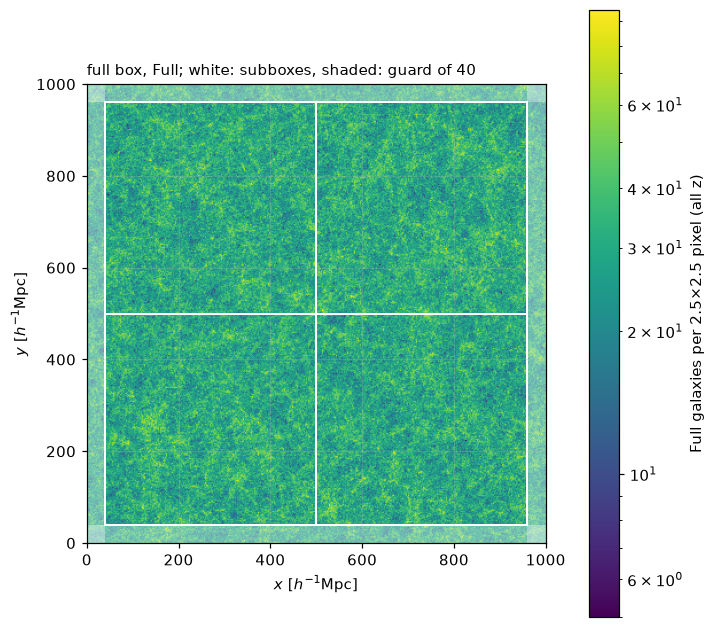

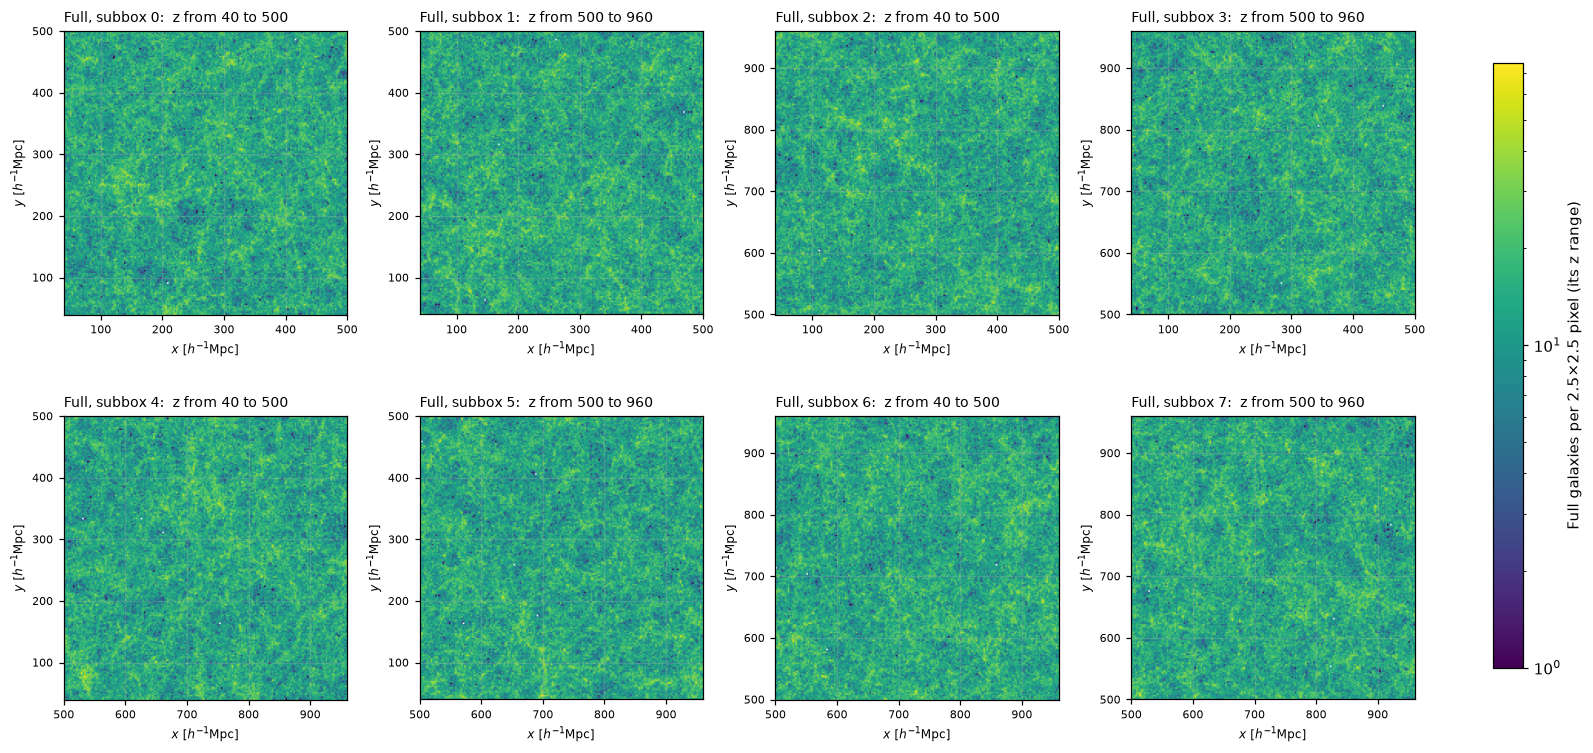

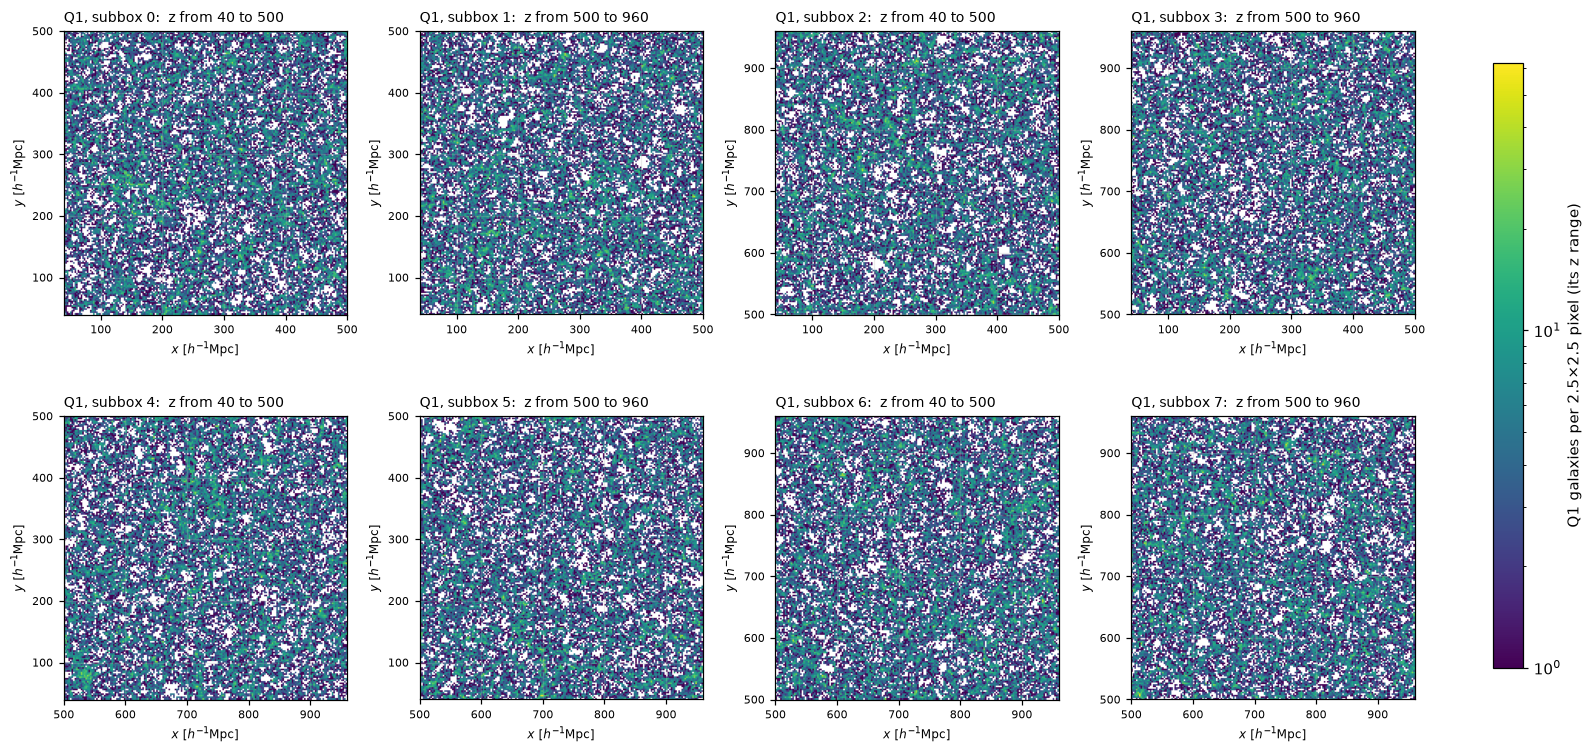

In [3]:
# projected number of galaxies of one sample (all z): the whole box, with the subboxes (solid) and the guard along the
# faces (shaded); then, for each sample in map_labs, each subbox in box coordinates, over its own x and y range (its z
# range in the title)
from matplotlib.colors import LogNorm
from matplotlib.patches import Rectangle
map_labs = [l for l in ('Full', 'Q1') if l in oct_samples] or oct_samples[:1]   # samples of the subbox maps
map_lab = map_labs[0]                                    # sample of the whole-box map
map_bin = 2.5                                            # [h^-1 Mpc] pixel size of the maps
p_box = pos_all if map_lab == 'Full' else None           # the full-box sample: Full is the whole catalogue
if p_box is None:                                        # other samples: the union of their subbox points (box coords)
    p_box = np.concatenate([POS[map_lab, j] + sub_bounds(j)[0] for j in SUBS])
eb = np.arange(0., L + map_bin, map_bin)
H, _, _ = np.histogram2d(p_box[:, 0], p_box[:, 1], bins=[eb, eb])
fig, ax = plt.subplots(figsize=(6.4, 5.6), layout='constrained')
im = ax.imshow(H.T, origin='lower', extent=[0, L, 0, L], norm=LogNorm(vmin=max(H[H > 0].min(), 1)), cmap='viridis')
fig.colorbar(im, ax=ax, label=f'{map_lab} galaxies per {map_bin:g}×{map_bin:g} pixel (all z)')
if face_guard > 0:                                       # the guard layer along the faces
    for (x0, w_) in ((0, face_guard), (L - face_guard, face_guard)):
        ax.add_patch(Rectangle((x0, 0), w_, L, color='w', alpha=0.35, lw=0))
        ax.add_patch(Rectangle((0, x0), L, w_, color='w', alpha=0.35, lw=0))
for j in SUBS:
    lo, hi = sub_bounds(j)
    ax.add_patch(Rectangle((lo[0], lo[1]), hi[0] - lo[0], hi[1] - lo[1], fill=False, ec='w', lw=1.2))
ax.set_xlim(0, L); ax.set_ylim(0, L); ax.set_aspect('equal')
ax.set_xlabel(r'$x\ [h^{-1}{\rm Mpc}]$'); ax.set_ylabel(r'$y\ [h^{-1}{\rm Mpc}]$')
ax.set_title(f'full box, {map_lab}; white: subboxes, shaded: guard of {face_guard:g}', fontsize=10, loc='left')
save_show('0_box_map')

ncol = min(n_sub, 4); nrow = -(-n_sub // ncol)
for lab_ in map_labs:                                    # one figure per sample (each its own colour scale; for Q1 its
    HS = {}                                              # per-subbox quartile, the one fitted in that subbox)
    for j in SUBS:
        lo, hi = sub_bounds(j); p = POS[lab_, j] + lo    # back to box coordinates
        ex = np.arange(lo[0], hi[0] + 1e-9, map_bin); ey = np.arange(lo[1], hi[1] + 1e-9, map_bin)
        HS[j] = (np.histogram2d(p[:, 0], p[:, 1], bins=[ex, ey])[0], lo, hi)
    vmax_ = max(h.max() for h, _, _ in HS.values()); vmin_ = max(min(h[h > 0].min() for h, _, _ in HS.values()), 1)
    fig, ax = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.5 * nrow), squeeze=False, layout='constrained')
    for j in SUBS:
        h, lo, hi = HS[j]; a = ax[j // ncol, j % ncol]
        im = a.imshow(h.T, origin='lower', extent=[lo[0], hi[0], lo[1], hi[1]], norm=LogNorm(vmin=vmin_, vmax=vmax_),
                      cmap='viridis')
        a.set_xlim(lo[0], hi[0]); a.set_ylim(lo[1], hi[1]); a.set_aspect('equal')
        a.set_title(f'{lab_}, subbox {j}:  z from {lo[2]:g} to {hi[2]:g}', fontsize=9, loc='left')
        a.set_xlabel(r'$x\ [h^{-1}{\rm Mpc}]$', fontsize=8); a.set_ylabel(r'$y\ [h^{-1}{\rm Mpc}]$', fontsize=8)
        a.tick_params(labelsize=7)
    for k_ in range(n_sub, nrow * ncol):
        ax[k_ // ncol, k_ % ncol].axis('off')
    fig.colorbar(im, ax=ax, label=f'{lab_} galaxies per {map_bin:g}×{map_bin:g} pixel (its z range)', shrink=0.8)
    save_show(f"0_subbox_maps_{lab_.replace(' ', '_')}")

**Check of the $d_{\rm fil}$ artifact near the box faces** (full box, no guard): the fraction of galaxies in the
full-box Q1, and the median $d_{\rm fil}$, against the distance to the nearest face of the box. Without the artifact the
fraction would be flat at 0.25.

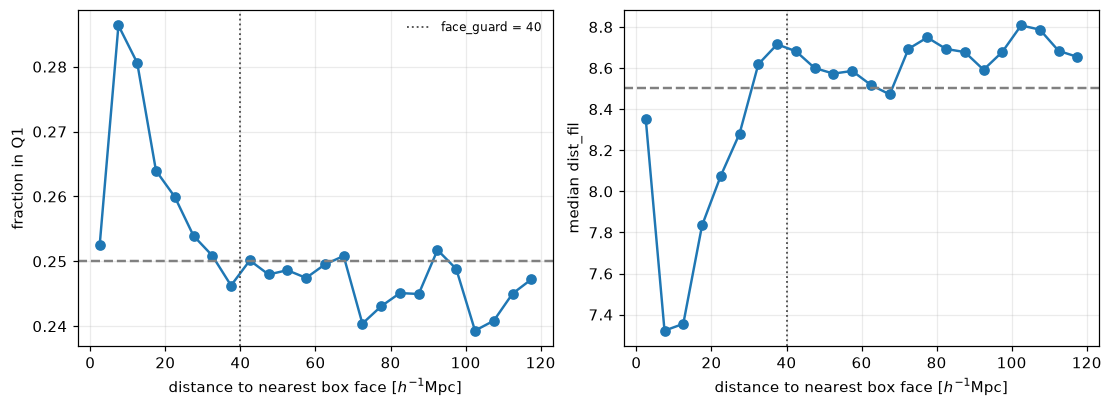

saved /home/federico/Proyectos/filbao/multidark/codes/figures/octant_test/dist_fil_Q4_mag-20.8_bin5_fit50-150_sub2/frac_Q1_vs_face.png


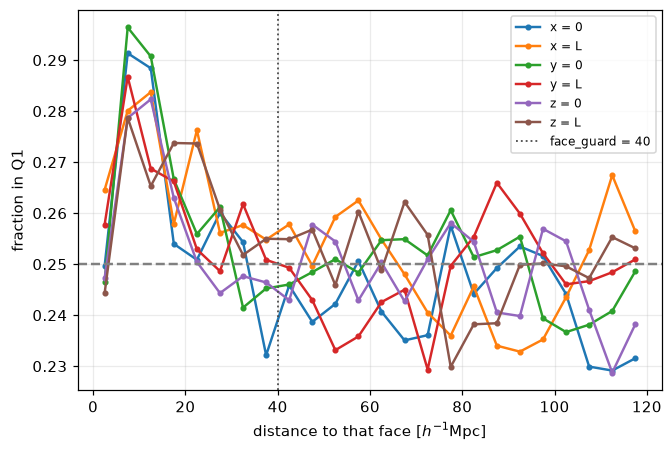

In [4]:
# fraction of galaxies in the full-box Q1, and median d_fil, against the distance to the nearest box face
d_face = np.minimum(pos_all, L - pos_all).min(axis=1)
v = cat[q_col].values
inQ1 = v < float(spec['split_edges'][1])                 # the full-box Q1 boundary
fb = np.arange(0., 125., 5.)                             # bins of distance to the face [h^-1 Mpc]
k = np.digitize(d_face, fb) - 1
ok = (k >= 0) & (k < len(fb) - 1)
n = np.bincount(k[ok], minlength=len(fb) - 1)
frac = np.bincount(k[ok], weights=inQ1[ok], minlength=len(fb) - 1) / n
med = [np.median(v[ok][k[ok] == i]) for i in range(len(fb) - 1)]
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
ax[0].plot(0.5 * (fb[1:] + fb[:-1]), frac, 'o-'); ax[0].axhline(0.25, color='0.5', ls='--')
for a_ in ax:                                            # the guard: galaxies left of it are dropped from the subboxes
    a_.axvline(face_guard, color='0.3', ls=':', lw=1.2, label=f'face_guard = {face_guard:g}')
ax[0].legend(fontsize=8, frameon=False)
ax[0].set_xlabel('distance to nearest box face [$h^{-1}$Mpc]'); ax[0].set_ylabel('fraction in Q1')
ax[1].plot(0.5 * (fb[1:] + fb[:-1]), med, 'o-'); ax[1].axhline(np.median(v), color='0.5', ls='--')
ax[1].set_xlabel('distance to nearest box face [$h^{-1}$Mpc]'); ax[1].set_ylabel(f'median {q_col}')
plt.show()

# fraction in Q1 against the distance to each of the six faces separately
v = cat[q_col].values
inQ1 = v < float(spec['split_edges'][1])
fb = np.arange(0., 125., 5.); cb = 0.5 * (fb[1:] + fb[:-1])
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for a, name in enumerate('xyz'):
    for side, d in (('0', pos_all[:, a]), ('L', L - pos_all[:, a])):
        k = np.digitize(d, fb) - 1; ok = (k >= 0) & (k < len(fb) - 1)
        frac = np.bincount(k[ok], weights=inQ1[ok], minlength=len(cb)) / np.bincount(k[ok], minlength=len(cb))
        ax.plot(cb, frac, 'o-', ms=3, label=f'{name} = {side}')
ax.axhline(0.25, color='0.5', ls='--')
ax.axvline(face_guard, color='0.3', ls=':', lw=1.2, label=f'face_guard = {face_guard:g}')
ax.set_xlabel('distance to that face [$h^{-1}$Mpc]'); ax.set_ylabel('fraction in Q1'); ax.legend(fontsize=8)
os.makedirs(FIG_DIR, exist_ok=True)
plt.savefig(os.path.join(FIG_DIR, f"frac_Q1_vs_face.{fig_formats[0]}"), dpi=150, bbox_inches='tight')
print(f"saved {os.path.join(FIG_DIR, f'frac_Q1_vs_face.{fig_formats[0]}')}")
plt.show()

**The same check with random points** (full box, no guard): random points uniform in the box give the volume of
each bin of distance to the nearest face (left: their counts, against the analytic volume of the shell between two
cubes). Right: the number density of the galaxies (Full, and the full-box Q1) in each bin relative to the random
points, $(N_{\rm gal}(d)/N_{\rm gal})\,/\,(N_{\rm rand}(d)/N_{\rm rand})$, with $d$ the distance to the nearest face; 1 for a sample
spread uniformly, whatever the geometry of the bins. Error bars: Poisson errors of the galaxy counts only. Below: Q1
against each of the six faces separately.

9999750 random points;  random counts / expected from the analytic volume, first bins: 0.999 0.998 1.002 1.000 1.000 0.997


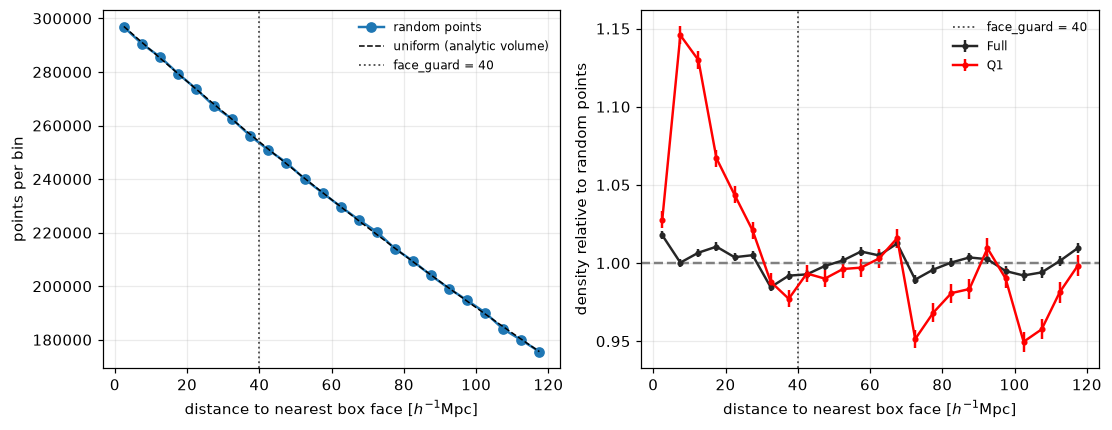

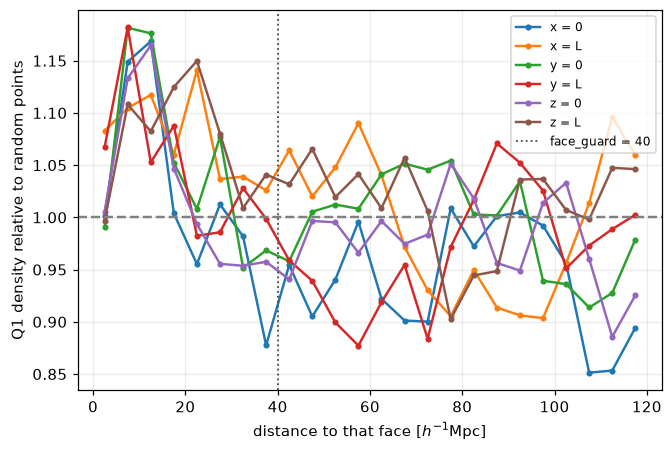

In [5]:
# number density of galaxies (Full, and the full-box Q1) against the distance to the box faces, relative to uniform
# random points: n_rand random points uniform in the box give the volume of each distance bin
n_rand = 2 * len(cat)                                    # number of random points
rpos = np.random.default_rng(0).uniform(0, L, (n_rand, 3))
fb = np.arange(0., 125., 5.); cb = 0.5 * (fb[1:] + fb[:-1])
inQ1 = cat[q_col].values < float(spec['split_edges'][1])  # the full-box Q1

def counts(d):
    # number of points in each bin of distance d
    k = np.digitize(d, fb) - 1; ok = (k >= 0) & (k < len(cb))
    return np.bincount(k[ok], minlength=len(cb)), k, ok

def density_ratio(d_gal, d_rand, sel):
    # (fraction of the galaxies in sel in each bin) / (fraction of the random points in that bin): 1 for a uniform sample
    # both normalized by their totals over the whole box (not only the binned range), so a uniform sample gives 1
    k, ok = counts(d_gal)[1:]
    use = ok if sel is None else ok & sel
    n_g = np.bincount(k[use], minlength=len(cb))
    n_r = counts(d_rand)[0]
    n_tot = len(d_gal) if sel is None else int(sel.sum())
    return (n_g / n_tot) / (n_r / n_rand), n_g

d_g = np.minimum(pos_all, L - pos_all).min(axis=1)       # distance to the nearest face
d_r = np.minimum(rpos, L - rpos).min(axis=1)
n_r = counts(d_r)[0]
vol = (L - 2 * fb[:-1])**3 - (L - 2 * fb[1:])**3          # analytic volume of each bin (shell between two cubes)
print(f"{n_rand} random points;  random counts / expected from the analytic volume, first bins: "
      + ' '.join(f'{x:.3f}' for x in (n_r / (n_rand * vol / L**3))[:6]))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), layout='constrained')
ax[0].plot(cb, n_r, 'o-', color='C0', label='random points')
ax[0].plot(cb, n_rand * vol / L**3, '--', color='k', lw=1, label='uniform (analytic volume)')
ax[0].set_ylabel('points per bin')
for lab_, sel, c in (('Full', None, '0.15'), ('Q1', inQ1, 'red')):
    r_, n_ = density_ratio(d_g, d_r, sel)
    e_ = r_ / np.sqrt(np.maximum(n_, 1))                 # Poisson error of the galaxy counts only
    ax[1].errorbar(cb, r_, e_, fmt='o-', ms=3, color=c, capsize=0, label=lab_)
ax[1].axhline(1, color='0.5', ls='--')
ax[1].set_ylabel('density relative to random points')
for a_ in ax:
    a_.axvline(face_guard, color='0.3', ls=':', lw=1.2, label=f'face_guard = {face_guard:g}')
    a_.set_xlabel('distance to nearest box face [$h^{-1}$Mpc]'); a_.legend(fontsize=8, frameon=False)
save_show('density_vs_face_randoms')

# the six faces separately: Q1 density relative to random points
fig, ax = plt.subplots(figsize=(6, 4), layout='constrained')
for a, name in enumerate('xyz'):
    for side, dg_, dr_ in (('0', pos_all[:, a], rpos[:, a]), ('L', L - pos_all[:, a], L - rpos[:, a])):
        ax.plot(cb, density_ratio(dg_, dr_, inQ1)[0], 'o-', ms=3, label=f'{name} = {side}')
ax.axhline(1, color='0.5', ls='--')
ax.axvline(face_guard, color='0.3', ls=':', lw=1.2, label=f'face_guard = {face_guard:g}')
ax.set_xlabel('distance to that face [$h^{-1}$Mpc]'); ax.set_ylabel('Q1 density relative to random points')
ax.legend(fontsize=8)
save_show('density_vs_face_randoms_6faces')
del rpos, d_r

## 2. Monopoles in the subboxes

As `multidark_correlation.compute_xi_s_mu` and `compute_monopole_from_xi_s_mu` do in the box: pair counts
$DD(s,\mu)$ (Corrfunc `DDsmu`, ordered pairs, $\mu=|\Delta z|/s$, as many $\mu$ bins in $[0,1]$ as $s$ bins),
$\xi(s,\mu)$ from them, and the monopole as the average of $\xi(s,\mu)$ over the $\mu$ bins,
$\hat\xi_{0}(s_i)=\frac{1}{n_\mu}\sum_k\hat\xi(s_i,\mu_k)$, with $n_\mu$ the number of $\mu$ bins. What changes: the subbox
is not periodic (`periodic=False`), so a galaxy near a face has fewer partners inside it.

**The window.** For a uniform sample in a rectangular box of sides $\ell_x,\ell_y,\ell_z$, the fraction of pairs at
separation $r$ and direction $\mu$ whose second member also falls inside it (averaged over the azimuth) is

$$
g(r,\mu)=\left(1-\frac{r\mu}{\ell_z}\right)\left(1-\frac{2(a_x+a_y)}{\pi}+\frac{a_xa_y}{\pi}\right),\qquad
a_x=\frac{r\sqrt{1-\mu^2}}{\ell_x},\quad a_y=\frac{r\sqrt{1-\mu^2}}{\ell_y},\qquad r\le\min(\ell_x,\ell_y,\ell_z),
$$

and for the cell of $s$ bin $i$ (edges $s_i^\pm$) and $\mu$ bin $k$ (edges $\mu_k^\pm$)

$$
W_{ik}=\int_{s_i^-}^{s_i^+}\!\!\int_{\mu_k^-}^{\mu_k^+}4\pi r^2\,g(r,\mu)\,d\mu\,dr,
$$

so a uniform sample of $N_A$ points and one of $N_B$ points in the same box have $N_AN_BW_{ik}/V$ expected pairs in the
cell, with $V=\ell_x\ell_y\ell_z$ (ordered pairs of one sample: $N(N-1)W_{ik}/V$). With $g=1$, $W_{ik}$ is the box's shell
volume times $\Delta\mu$, and $N(N-1)W_{ik}/V$ is the box's analytic $RR$.

**Why not the box's estimator, DD/RR − 1 (`estimator = 'natural'`).** In the periodic box every galaxy has the same
number of potential partners at every $s$. In a subbox, galaxies near the faces have fewer, so $DD$ weights the
interior more than the edges, and more so at larger $s$. If the interior of a subbox is denser than its edges by
$\Delta$ (a long-wavelength mode of the simulation), $DD/RR-1$ picks up a term of order $2\Delta$ times the fraction of
pairs lost at that $s$. At first order in the density, and growing with $s$. For 460 h⁻¹Mpc subboxes, $\Delta$ of a few
per cent between interior and edges gives offsets of $10^{-2}$ at 150 h⁻¹Mpc, larger than the BAO.

**Landy–Szalay (`estimator = 'LS'`, default).** Random points $R$ (uniform in the subbox, `n_random_factor` times the
largest sample in it, seed `random_seed`) measure that weighting on the actual galaxies through the cross pairs $DR$:

$$
\boxed{\;\hat\xi_j(s_i,\mu_k)=\frac{DD_j}{N_D(N_D-1)W_{ik}/V}-2\,\frac{DR_j}{N_DN_RW_{ik}/V}+1\;}
$$

with $N_D$ the sample's galaxies in subbox $j$, $N_R$ the random points, $DD_j$ the ordered galaxy pairs and $DR_j$ the
galaxy–random pairs in the cell. The $RR$ term is the exact expectation (no random–random counts needed). The term
of first order in the density cancels between $DD$ and $DR$ (Landy & Szalay 1993); what remains is second order (and
the integral constraint, close to a constant in $s$, absorbed by the broadband's constant term). The random points
add noise to $DR$ that falls as $1/N_R$.

Files, named as the script's with `_subsim<n_side>g<face_guard>` added to the label: pair counts in
`data/processed/pair_counts/subboxes` ($DD$ files shared by both estimators, $DR$ files with `_DR<factor>s<seed>`;
reused unless `force_paircounts`), monopoles (s, xi0, n_gal) in `data/processed/monopoles/subboxes` (`_LS` added for
Landy–Szalay). With `check_estimator`, the cell first applies the estimator to uniform random points in one subbox,
where $\hat\xi_0$ should scatter around 0.

The figure (section 3): for each sample, the subbox monopoles (thin), their mean (dashed) and the full-box monopole
(thick), with $b^2\xi_{\rm lin}$ (dotted; the full box's $b$).

In [6]:
PC_DIR = os.path.join(REPO, 'data/processed/pair_counts/subboxes')
params = dict(mag_max=mag, min_sep=mono_sep[0], max_sep=mono_sep[1], bin_size=binsep)
mu_edges = np.linspace(0., 1., len(edges))                 # as many mu bins as s bins (compute_xi_s_mu)
_W = {}

def window_W(side):
    # W(s, mu): the integral of 4 pi r^2 g(r, mu) over each (s, mu) cell, for a rectangular box of sides side = (l_x, l_y,
    # l_z) (text above), with 8 x 8 Gauss-Legendre points; the expected pair counts are N_A N_B W / (l_x l_y l_z)
    key = tuple(np.round(side, 6))
    if key not in _W:
        x, w = np.polynomial.legendre.leggauss(8)
        W = np.zeros((len(edges) - 1, len(mu_edges) - 1))
        for i in range(len(edges) - 1):
            hr = 0.5 * (edges[i + 1] - edges[i]); r, wr = hr * x + edges[i] + hr, hr * w
            for k in range(len(mu_edges) - 1):
                hm = 0.5 * (mu_edges[k + 1] - mu_edges[k]); mu, wm = hm * x + mu_edges[k] + hm, hm * w
                R, M = np.meshgrid(r, mu, indexing='ij')
                ax_, ay_ = R * np.sqrt(1 - M**2) / side[0], R * np.sqrt(1 - M**2) / side[1]
                g = (1 - R * M / side[2]) * (1 - 2 * (ax_ + ay_) / np.pi + ax_ * ay_ / np.pi)
                W[i, k] = np.sum(np.outer(wr, wm) * 4 * np.pi * R**2 * g)
        _W[key] = W
    return _W[key]

def pair_counts(p, q=None, pc_file=None):
    # DD(s, mu) of the points p (q None: autocorr, ordered pairs) or D R(s, mu) of p with q (cross, each pair once), with
    # DDsmu (periodic=False); read from pc_file if saved (unless force_paircounts), else counted and saved there
    if pc_file and os.path.exists(pc_file) and not force_paircounts:
        return np.load(pc_file)['H_dd']
    x, y, z = (np.ascontiguousarray(p[:, a]) for a in range(3))
    kw = dict(autocorr=1) if q is None else dict(autocorr=0, X2=np.ascontiguousarray(q[:, 0]),
                                                  Y2=np.ascontiguousarray(q[:, 1]), Z2=np.ascontiguousarray(q[:, 2]))
    H = DDsmu(nthreads=nthreads, binfile=edges, mu_max=1.0, nmu_bins=len(mu_edges) - 1, X1=x, Y1=y, Z1=z,
              periodic=False, verbose=False, **kw)['npairs']
    H = H.reshape(len(edges) - 1, len(mu_edges) - 1).astype(np.float64)
    if pc_file:
        os.makedirs(os.path.dirname(pc_file), exist_ok=True)
        np.savez(pc_file, s_bins=edges, mu_bins=mu_edges, H_dd=H)
    return H

def xi_smu(p, side, rand=None, pc_dd=None, pc_dr=None):
    # xi(s, mu) of the points p (the subbox's frame, sides `side`): natural estimator DD / <DD> - 1, or Landy-Szalay
    # DD / <DD> - 2 DR / <DR> + 1 with the random points rand (text above); <.> the expected counts of a uniform sample
    W, V, N = window_W(side), float(np.prod(side)), len(p)
    with np.errstate(divide='ignore', invalid='ignore'):
        xi = pair_counts(p, None, pc_dd) / (N * (N - 1) / V * W) - 1.0
        if rand is not None:
            xi -= 2 * (pair_counts(p, rand, pc_dr) / (N * len(rand) / V * W) - 1.0)
    return xi

def randoms(j):
    # uniform random points in subbox j (its frame): n_random_factor x the largest sample of oct_samples in it
    n_r = int(round(n_random_factor * max(len(POS[l, j]) for l in oct_samples)))
    return np.random.default_rng([random_seed, j]).uniform(0, SIDE[j], (n_r, 3))

if check_estimator:
    pr = np.random.default_rng(1).uniform(0, SIDE[0], (n_random_check, 3))
    rr_ = (np.random.default_rng(2).uniform(0, SIDE[0], (int(n_random_factor * n_random_check), 3))
           if estimator == 'LS' else None)
    xr = compute_monopole_from_xi_s_mu(xi_smu(pr, SIDE[0], rr_))
    m = (s_c >= fit_range[0]) & (s_c <= fit_range[1])
    print(f"estimator ({estimator}) on {n_random_check} uniform random points in one subbox, fit range: mean xi_0 = "
          f"{xr[m].mean():+.1e}, rms = {xr[m].std():.1e}  (should scatter around 0; the bins move together)")

os.makedirs(SUB_DIR, exist_ok=True)
tag = f"_subsim{n_side}g{face_guard:g}"
rtag = f"_DR{n_random_factor:g}s{random_seed}" if estimator == 'LS' else ''
XI = {}                                                   # (sample, subbox) -> xi_0 on s_c; plus (sample, 'box')
t0 = time.time()
for j in SUBS:
    rand = randoms(j) if estimator == 'LS' else None
    for lab in oct_samples:
        desc = f"{DESC[lab, j]}{tag}-{j}"
        xi0 = compute_monopole_from_xi_s_mu(xi_smu(
            POS[lab, j], SIDE[j], rand, get_save_filename(desc, params, PC_DIR, filetype='paircounts'),
            get_save_filename(f"{DESC[lab, j]}{tag}{rtag}-{j}", params, PC_DIR, filetype='paircounts')))
        np.savez(get_save_filename(f"{DESC[lab, j]}{tag}{'_LS' if estimator == 'LS' else ''}-{j}", params, SUB_DIR,
                                   filetype='monopole'), s=s_c, xi0=xi0, n_gal=len(POS[lab, j]))
        XI[lab, j] = xi0
    print(f"subbox {j}: monopoles of {', '.join(oct_samples)}" + (f" ({len(rand)} randoms)" if rand is not None else '')
          + f"   ({time.time() - t0:.0f} s)")
for lab in oct_samples:
    s_b, XI[lab, 'box'], _ = bf.load_monopole(os.path.join(MONO, f"mag={mag:.1f}_sep={mono_sep[0]:.1f}-"
                                                                f"{mono_sep[1]:.1f}_binsep={binsep:.1f}_{samples[lab]}.npz"))
    assert np.allclose(s_b, s_c), f"{lab}: box monopole on different bins"

estimator (LS) on 200000 uniform random points in one subbox, fit range: mean xi_0 = +2.8e-04, rms = 1.0e-04  (should scatter around 0; the bins move together)
subbox 0: monopoles of Full, Q1, Full dil nQ (4868200 randoms)   (0 s)
subbox 1: monopoles of Full, Q1, Full dil nQ (4937760 randoms)   (0 s)
subbox 2: monopoles of Full, Q1, Full dil nQ (4848740 randoms)   (0 s)
subbox 3: monopoles of Full, Q1, Full dil nQ (4811940 randoms)   (1 s)
subbox 4: monopoles of Full, Q1, Full dil nQ (4805850 randoms)   (1 s)
subbox 5: monopoles of Full, Q1, Full dil nQ (4769870 randoms)   (1 s)
subbox 6: monopoles of Full, Q1, Full dil nQ (4943190 randoms)   (1 s)
subbox 7: monopoles of Full, Q1, Full dil nQ (4922240 randoms)   (1 s)


## 3. Bias and covariance

Both are built with the recipe of `desilike_fits.ipynb` section 1: the bias $b$ fitted on ξ₀ over 30–75 h⁻¹Mpc
(`bf.estimate_bias_independent`, "undetermined" if unstable), and the Gaussian covariance `bf.gaussian_cov_pk` from
the measured auto-spectrum $P(k)$ (shot noise included), with the low-k model $A\,M(k)$ on the shells below `k_model`
(not for a sample whose $b$ is undetermined). What changes with `independent`:

* **`independent = True`:** every subbox is treated as a survey of its own. $b$ is fitted on the subbox's ξ₀ (with
  its own number density, $N_j/(\ell_x\ell_y\ell_z)$); $P(k)$ is measured in the subbox (`multidark_power.measure_spectra`,
  positions in the subbox's frame, a cube of side $\ell$ (`ng` scaled by $\ell/L$ so the cell size is the box's), the same
  foldings, so the same reach in $k$); the low-k model's $A$ is fitted on the subbox's own spectrum; the covariance is
  summed over the subbox's own modes, $\mathbf{k}=2\pi\mathbf{n}/\ell$, with its volume $\ell^3$. Saved
  to `data/processed/pk/subboxes` (reused unless `force_spectra`).
* **`independent = False`:** the full box's $b$ and covariance, scaled to the subbox volume (a Gaussian covariance
  scales as one over the volume):
$$
\boxed{\;C_{\rm sub}=\frac{L^3}{\ell_x\ell_y\ell_z}\,C_{\rm box}\;}
$$

**What the subbox spectrum is.** The subbox is not periodic, but the FFT treats it as if it were. Its Fourier modes
then see the true $P(k)$ averaged over a range $\sim 2\pi/\ell$ ($0.014\,h/$Mpc for the octants) around each
$k$: negligible where $P$ varies slowly, so the effect is on the lowest shells, the ones the low-k model replaces.
Folding stays exact (each folded mode is a mode of the subbox). Neither version includes the subbox edges in the
covariance (fewer pairs at large $s$, so somewhat more shot noise there).

The cell prints, for every sample and subbox, $b$, $A$ and the error $\sigma$ of ξ₀ at the bin nearest 100 h⁻¹Mpc,
next to the full box's times $\sqrt{L^3/(\ell_x\ell_y\ell_z)}$ (subbox 0's volume). $b$ enters the covariance (below `k_model`) and the division by
$b^2$ in the figures. The monopole figure shows $b^2\xi_{\rm lin}$ with the full box's $b$.

WARNING bias estimate unstable across ranges: (30, 60): 1.122, (40, 70): 0.866, (35, 75): 0.963  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
WARNING bias estimate unstable across ranges: (30, 60): 1.243, (40, 70): 1.067, (35, 75): 1.170  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
WARNING bias estimate unstable across ranges: (30, 60): 1.390, (40, 70): 1.050, (35, 75): 1.215  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
WARNING bias estimate unstable across ranges: (30, 60): 1.381, (40, 70): 1.185, (35, 75): 1.258  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
WARNING bias estimate unstable across ranges: (30, 60): 0.834, (40, 70): 0.672, (35, 75): 0.745  -> check the monopole at 30-75 h^-1 Mpc; the covariance scales as b^4 below k_lo of spectrum_for_cov
WARNING bi

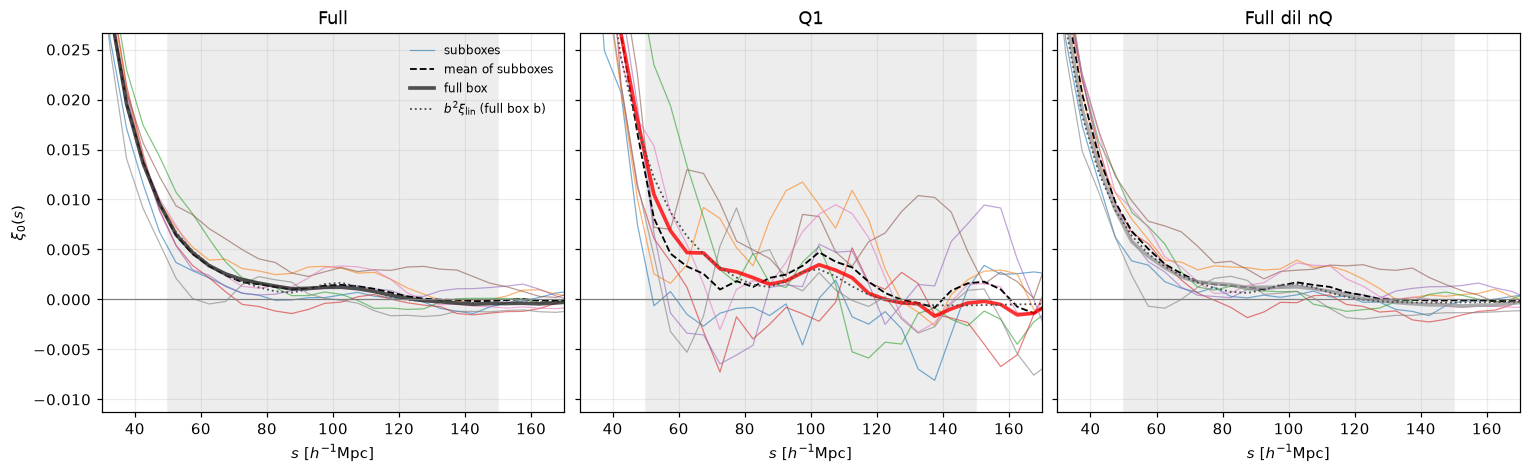

In [7]:
lin = bf.linear_theory()
k_lin, P_w, P_nw = bf.generate_templates(lin=lin)
T = bf.BAOTemplate(k_lin, P_w, P_nw, lin)
Sigma_th = bf.sigma_nl_theory(lin)['Sigma_mono']
C0 = bf.COSMO
cosmo = Cosmology(h=C0['H0'] / 100., omega_b=C0['ombh2'], omega_cdm=C0['omch2'], A_s=C0['As'], n_s=C0['ns'],
                  m_ncdm=[] if C0.get('mnu', 0.06) == 0 else [C0['mnu']], engine='camb')
cov_set = {n: p.default for n, p in inspect.signature(bf.spectrum_for_cov).parameters.items()
           if p.default is not inspect.Parameter.empty}

def lowk_model_spectra(spec, b_of):
    # as desilike_fits section 1: copy of the spectra with A_ij M_ij(k) on the shells k < k_model, M = b_i b_j P_lin + N_ij
    kk, nk = spec['k'], spec['nmodes']
    Plin = np.exp(np.interp(np.log(kk), np.log(lin['kh']), np.log(lin['pk'])))
    mW, mlo = (kk >= lowk_window[0]) & (kk <= lowk_window[1]), kk < k_model
    mN = (kk >= cov_set['n_win'][0]) & (kk <= cov_set['n_win'][1])
    out, A = dict(spec, P=spec['P'].copy()), {}
    for i, bi in b_of.items():
        for j, bj in b_of.items():
            if j < i:
                continue
            P = spec['P'][i, j]; lin_ij = bi * bj * Plin
            N = np.sum((P - lin_ij)[mN] * nk[mN]) / nk[mN].sum()
            M = lin_ij + N
            A[i, j] = A[j, i] = np.sum(nk[mW] * (P / M)[mW]) / nk[mW].sum()
            out['P'][i, j] = out['P'][j, i] = np.where(mlo, A[i, j] * M, P)
    return out, A

def bias_of(xi, n_gal, L_vol):
    # (b, b_ok) fitted on xi_0 of a sample with n_gal galaxies in a cube of side L_vol (desilike_fits section 1)
    r = bf.estimate_bias_independent(s_c, xi, edges, n_gal / L_vol**3, T, L_vol)
    return r['b'], r['b_ok']

def cov_of(spec_v, i, b, b_ok):
    # covariance of sample i of the spectra spec_v (in the volume spec_v['L']^3), with the low-k model if b is
    # determined; returns C and A (None without the low-k model)
    sp, A = lowk_model_spectra(spec_v, {i: b}) if (lowk_model and b_ok) else (spec_v, {})
    return bf.gaussian_cov_pk(edges, sp, [i], [b], lin), A.get((i, i))

def sub_spectra(j):
    # auto/cross spectra of oct_samples in subbox j, measured as a periodic cube of its side with the box's cell size
    # and foldings; read from PK_SUB if saved for the same samples (unless force_spectra)
    f = os.path.join(PK_SUB, f"pk_XISMU_box_mag{mag:.1f}_{split_name}_subsim{n_side}g{face_guard:g}-{j}.npz")
    labels = [DESC[l, j] for l in oct_samples]
    if os.path.exists(f) and not force_spectra:
        sp = bf.load_spectra(f)
        if sp['labels'] == labels:
            return sp
    pos_list = [POS[l, j] for l in oct_samples]
    assert np.allclose(SIDE[j], SIDE[j][0]), f"subbox {j} is not a cube ({SIDE[j]}): its spectrum needs one"
    ell = float(SIDE[j][0])
    out = measure_spectra(pos_list, labels, ell, ng=2 * int(round(int(spec['ng']) * ell / L / 2)), n_fold=int(spec['n_fold']),
                          kuse_frac=float(spec['kuse_frac']))
    os.makedirs(PK_SUB, exist_ok=True); np.savez(f, **out)
    return bf.load_spectra(f)

m_fit = (s_c >= fit_range[0]) & (s_c <= fit_range[1])
i_spec = {lab: spec['labels'].index(samples[lab]) for lab in oct_samples}
BIAS, COV, AL = {}, {}, {}                                # (sample, subbox or 'box') -> (b, b_ok), C, A
for lab in oct_samples:                                   # full box: as desilike_fits section 1
    BIAS[lab, 'box'] = bias_of(XI[lab, 'box'], n_of(samples[lab]), L)
    COV[lab, 'box'], AL[lab, 'box'] = cov_of(spec, i_spec[lab], *BIAS[lab, 'box'])
t0 = time.time()
for j in SUBS:
    if independent:
        sp = sub_spectra(j)
    for i, lab in enumerate(oct_samples):
        if independent:
            BIAS[lab, j] = bias_of(XI[lab, j], int(sp['n_gal'][i]), float(np.prod(SIDE[j]))**(1 / 3))
            COV[lab, j], AL[lab, j] = cov_of(sp, i, *BIAS[lab, j])
        else:
            BIAS[lab, j], COV[lab, j], AL[lab, j] = BIAS[lab, 'box'], L**3 / np.prod(SIDE[j]) * COV[lab, 'box'], AL[lab, 'box']
if independent:
    print(f"subbox spectra: {n_sub} subboxes in {time.time() - t0:.0f} s ({os.path.relpath(PK_SUB, REPO)})")

D = {}                                                    # (sample, subbox or 'box') -> data of one fit
for lab in oct_samples:
    for j in SUBS + ['box']:
        (b, b_ok), C = BIAS[lab, j], COV[lab, j]
        D[lab, j] = dict(s=s_c, xi=XI[lab, j], edges=edges, m=m_fit, C=C, sig=np.sqrt(np.diag(C)), b=b, b_ok=b_ok)

i100 = int(np.argmin(np.abs(s_c - 100.)))
fb = lambda bb: f"{bb[0]:.3f}" + ('' if bb[1] else '?')
fa = lambda A: '-' if A is None else f"{A:.2f}"
print(f"b ('?': undetermined), A of the low-k model ('-': not applied), sigma of xi_0 at s = {s_c[i100]:g} "
      f"[1e-3];  last line: the full box, its sigma x sqrt(L^3 / V of subbox 0) = {np.sqrt(L**3 / np.prod(SIDE[0])):.2f}")
for lab in oct_samples:
    print(f"{lab}\n{'':>6} | {'b':>7} | {'A':>5} | {'sigma':>7}")
    for j in SUBS:
        print(f"{j:>6} | {fb(BIAS[lab, j]):>7} | {fa(AL[lab, j]):>5} | {D[lab, j]['sig'][i100] * 1e3:7.3f}")
    print(f"{'box':>6} | {fb(BIAS[lab, 'box']):>7} | {fa(AL[lab, 'box']):>5} | "
          f"{D[lab, 'box']['sig'][i100] * 1e3 * np.sqrt(L**3 / np.prod(SIDE[0])):7.3f}")

# figure: subbox monopoles against the full box (y range from the fit range)
xi_lin = T.xi(0., edges=edges)
fig, ax = plt.subplots(1, len(oct_samples), figsize=(4.6 * len(oct_samples), 4.2), sharey=True, layout='constrained')
for a, lab in zip(np.atleast_1d(ax), oct_samples):
    for j in SUBS:
        a.plot(s_c, XI[lab, j], lw=0.8, alpha=0.6, label='subboxes' if j == 0 else None)
    a.plot(s_c, np.mean([XI[lab, j] for j in SUBS], axis=0), 'k--', lw=1.2, label='mean of subboxes')
    a.plot(s_c, XI[lab, 'box'], color=SCOL.get(lab, 'k'), lw=2.4, alpha=0.8, label='full box')
    if BIAS[lab, 'box'][1]:
        a.plot(s_c, BIAS[lab, 'box'][0]**2 * xi_lin, ':', color='0.3', lw=1.2, label=r'$b^2\xi_{\rm lin}$ (full box b)')
    a.axvspan(*fit_range, color='0.93', zorder=0); a.axhline(0, color='0.5', lw=0.8)
    a.set_xlim(fit_range[0] - 20, fit_range[1] + 20); a.set_title(lab); a.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
lo = min(np.nanmin(XI[l, j][m_fit]) for l in oct_samples for j in SUBS)
hi = max(np.nanmax(XI[l, j][m_fit]) for l in oct_samples for j in SUBS)
np.atleast_1d(ax)[0].set_ylim(lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo))
np.atleast_1d(ax)[0].set_ylabel(r'$\xi_0(s)$'); np.atleast_1d(ax)[0].legend(fontsize=8, frameon=False)
save_show('1_monopoles')

## 4. The fits

The functions are copied from `desilike_fits.ipynb` section 2 and must stay identical to them: α fit (Gaussian Σ
prior; α and its Δχ² = 1 interval), Σ fit (flat prior `Sigma_free`; Σ and its Δχ² = 1 interval from the profile
χ²(Σ) in steps of `Sigma_step`), the no-wiggle fit (for $\Delta\chi^2_{\rm det}$, as in `desilike_fits.ipynb`), and the template-free Gaussian peak (centre μ, width $w$, with its Δχ² = 1 interval
from the profile in $w$). An interval that reaches the end of its range is marked `edge`. The range of $w$ is set as in `desilike_fits.ipynb`: from one bin width to $w_T(\Sigma_{\max})$, the width
the Gaussian fit gives on the noiseless template damped by the largest Σ of `Sigma_free` (Full's full-box bins and
covariance). Every sample is fitted in every subbox and in the full box; a fit that fails is kept as nan.

In [8]:
def desilike_theory(prior='gauss', only_now=False):
    # the BAO model of all fits (one sample); returns the theory and its template
    tpl = BAOPowerSpectrumTemplate(z=0., fiducial=cosmo, apmode='qiso', with_now='wallish2018', only_now=only_now)
    th = DampedBAOWigglesTracerCorrelationFunctionMultipoles(ells=(0,), template=tpl, broadband='power')
    P = th.init.params
    P['dbeta'].update(value=0., fixed=True)
    P['sigmas'].update(value=0., fixed=True)
    if prior == 'gauss':
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(dist='norm', loc=Sigma_th, scale=Sigma_prior_sd, limits=[0., 30.]))
    else:
        P['sigmaper'].update(fixed=False, value=Sigma_th, prior=dict(limits=list(Sigma_free)))
    P['sigmapar'].update(derived='{sigmaper}')
    for name in ('al0_1', 'al0_2'):
        P[name].update(value=0., fixed=True)
    if only_now:
        P['sigmaper'].update(fixed=True, value=Sigma_th, prior=None)
        tpl.init.params['qiso'].update(fixed=True, value=1.)
    return th, tpl

def desilike_lik(d, prior='gauss', only_now=False):
    th, _ = desilike_theory(prior, only_now)
    m = d['m']
    obs = TracerCorrelationFunctionMultipolesObservable(
        data=d['xi'][m], s=d['s'][m], covariance=d['C'][np.ix_(m, m)],
        slim={0: (fit_range[0], fit_range[1], binsep)}, wmatrix={'resolution': 10}, theory=th)
    return ObservablesGaussianLikelihood(observables=[obs]), obs

def desilike_fit(lik, interval=False):
    prof = MinuitProfiler(lik, seed=42)
    prof.maximize(niterations=5)
    b = prof.profiles.bestfit
    i = int(np.argmax(b.logposterior))
    pars = {p.name: float(b[p.name][i]) for p in lik.varied_params}
    out = dict(prof=prof, pars=pars, chi2=-2 * float(b['loglikelihood'][i]))
    if interval:
        prof.interval(params=['qiso'])
        iv = prof.profiles.interval['qiso']
        lo, hi = pars['qiso'] + iv[0], pars['qiso'] + iv[1]
        # desilike stops the interval at the prior edges (0.8, 1.2): report that as open
        out['lo'] = np.nan if lo <= 0.8 + 1e-3 else lo
        out['hi'] = np.nan if hi >= 1.2 - 1e-3 else hi
    return out

def interval_68(x, dchi2):
    # Delta chi2 = 1 interval around the minimum of a profile, crossings interpolated linearly between
    # grid points; nan on a side where Delta chi2 stays below 1 up to the end of the grid
    i0 = int(np.argmin(dchi2))
    up = [i for i in range(i0, len(x)) if dchi2[i] > 1]
    dn = [i for i in range(i0, -1, -1) if dchi2[i] > 1]
    hi = np.interp(1., dchi2[[up[0] - 1, up[0]]], x[[up[0] - 1, up[0]]]) if up else np.nan
    lo = np.interp(1., dchi2[[dn[0] + 1, dn[0]]], x[[dn[0] + 1, dn[0]]]) if dn else np.nan
    return lo, hi

def sigma_profile(lik, Sigma_best, grid=None):
    # Delta chi2(Sigma) = chi2_prof(Sigma) - chi2_min on a grid over Sigma_free (all other varied parameters
    # refitted at each point), its Delta chi2 = 1 interval, its value at Sigma_th and at Sigma = 0 (the
    # undamped, linear-theory peak; the start of the grid).  lo / hi = nan: the interval reaches the edge
    # of Sigma_free on that side.  grid: the Sigma values to profile (default: Sigma_free in steps of
    # Sigma_step); Sigma_th and Sigma_best are always added.
    if grid is None:
        grid = np.arange(Sigma_free[0], Sigma_free[1] + 1e-9, Sigma_step)
    grid = np.union1d(grid, [Sigma_th, Sigma_best])
    prof = MinuitProfiler(lik, seed=42)
    prof.profile(params=['sigmaper'], grid=grid)
    pr = np.asarray(prof.profiles.profile['sigmaper'])
    S, dchi2 = pr[:, 0], -2 * (pr[:, 1] - pr[:, 1].max())     # flat prior: log-posterior = log-likelihood + const
    lo, hi = interval_68(S, dchi2)
    return dict(S=S, dchi2=dchi2, lo=lo, hi=hi, dchi2_th=float(dchi2[np.argmin(np.abs(S - Sigma_th))]),
                dchi2_0=max(0., float(dchi2[np.argmin(np.abs(S - 0.))])))

mu_grid = np.arange(peak_mu_range[0], peak_mu_range[1] + 1e-9, peak_step)
# w_grid (range of the width w): set below, after peak_fit

def gauss_bins(edges, mu, w):
    # a unit-height Gaussian exp(-(s - mu)^2 / 2 w^2) averaged over each bin [e_i, e_i+1]
    z = (edges - mu) / (np.sqrt(2) * w)
    return np.sqrt(np.pi / 2) * w * np.diff(erf(z)) / np.diff(edges)

def refine(x, p):
    # minimum of a profile p on the grid x, refined by a parabola through the 3 points around it (at a grid edge: as is)
    i = int(np.argmin(p))
    if 0 < i < len(x) - 1:
        y0, y1, y2 = p[i - 1:i + 2]; den = y0 - 2 * y1 + y2
        if den > 0:
            return float(x[i] + 0.5 * (x[1] - x[0]) * (y0 - y2) / den)
    return float(x[i])

def peak_fit(s, xi, Cf):
    # template-free peak (section 2 text): smooth curve (template xi_nw + a0 + a1/s + a2/s^2) plus a Gaussian
    # h exp(-(s - mu)^2 / 2 w^2), fitted jointly to the bins s with covariance Cf. For fixed (mu, w) linear in
    # (c, a0, a1, a2, h): exact GLS on the grid mu_grid x w_grid; h < 0 -> no peak, the smooth curve alone.
    edges = bf.edges_from_centres(s); Ci = np.linalg.inv(Cf)
    X0 = bf.design_nowiggle(T, edges)
    def gls(X):
        th = np.linalg.solve(X.T @ Ci @ X, X.T @ Ci @ xi); r = xi - X @ th
        return float(r @ Ci @ r), th
    chi2_0 = gls(X0)[0]                                           # smooth curve alone
    chi2 = np.full((len(mu_grid), len(w_grid)), chi2_0)
    for i, mu in enumerate(mu_grid):
        for j, w in enumerate(w_grid):
            c2, th = gls(np.column_stack([X0, gauss_bins(edges, mu, w)]))
            if th[-1] > 0:
                chi2[i, j] = c2
    pm, pw = chi2.min(1) - chi2.min(), chi2.min(0) - chi2.min()  # profiles in mu and in w
    i, j = np.unravel_index(np.argmin(chi2), chi2.shape)
    th = gls(np.column_stack([X0, gauss_bins(edges, mu_grid[i], w_grid[j])]))[1]
    return dict(mu=refine(mu_grid, pm), w=refine(w_grid, pw), h=max(th[-1], 0.), mu_iv=interval_68(mu_grid, pm),
                w_iv=interval_68(w_grid, pw), prof_mu=pm, prof_w=pw, dchi2_peak=chi2_0 - chi2.min(),
                s=s, smooth=X0 @ th[:-1], sig=np.sqrt(np.diag(Cf)))

if peak_w_range is None:                                  # as desilike_fits section 2
    w_grid = np.arange(binsep, 40. + 1e-9, peak_step)     # temporary, only to find w_T
    d0 = D['Full', 'box'] if ('Full', 'box') in D else D[oct_samples[0], 'box']
    wT = peak_fit(s_c[m_fit], T.xi(Sigma_free[1], edges=bf.edges_from_centres(s_c[m_fit])),
                  d0['C'][np.ix_(m_fit, m_fit)])['w']
    assert wT < w_grid[-1] - peak_step, f"w_T(Sigma_free[1]) = {wT:.1f} at the end of the temporary grid"
    peak_w_range = (binsep, round(wT / peak_step) * peak_step)
    print(f"peak width range: w from {peak_w_range[0]:g} to {peak_w_range[1]:g} h^-1 Mpc (w_T at Sigma = {Sigma_free[1]:g}: {wT:.1f})")
w_grid = np.arange(peak_w_range[0], peak_w_range[1] + 1e-9, peak_step)

def fit_one(d):
    # the fits of one sample in one volume: alpha fit and Sigma fit (each with its 68% interval), Gaussian peak
    lik_a, obs_a = desilike_lik(d, 'gauss'); f_a = desilike_fit(lik_a, interval=True)
    lik_S, obs_S = desilike_lik(d, 'flat');  f_S = desilike_fit(lik_S)
    pS = sigma_profile(lik_S, f_S['pars']['sigmaper'])
    f_n = desilike_fit(desilike_lik(d, only_now=True)[0])                       # no-wiggle fit, for dchi2_det
    chi2 = f_a['chi2'] + ((f_a['pars']['sigmaper'] - Sigma_th) / Sigma_prior_sd)**2      # as desilike_fits section 2
    lik_S(**f_S['pars']); model_S = np.array(obs_S.flattheory)
    m = d['m']; g = peak_fit(d['s'][m], d['xi'][m], d['C'][np.ix_(m, m)])
    return dict(alpha=f_a['pars']['qiso'], a_lo=f_a['lo'], a_hi=f_a['hi'], Sigma=f_S['pars']['sigmaper'],
                S_lo=pS['lo'], S_hi=pS['hi'], alpha_S=f_S['pars']['qiso'], det=f_n['chi2'] - chi2, mu=g['mu'], w=g['w'], w_lo=g['w_iv'][0],
                w_hi=g['w_iv'][1], h=g['h'], dchi2_peak=g['dchi2_peak'], smooth=g['smooth'], model_S=model_S)

KEYS = ('alpha', 'a_lo', 'a_hi', 'Sigma', 'S_lo', 'S_hi', 'alpha_S', 'det', 'mu', 'w', 'w_lo', 'w_hi', 'h', 'dchi2_peak')
R = {}
t0 = time.time()
for lab in oct_samples:
    for j in ['box'] + SUBS:
        try:
            R[lab, j] = fit_one(D[lab, j])
        except Exception as e:                            # keep going: a failed fit is nan
            print(f"  FIT FAILED {lab}, subbox {j}: {type(e).__name__}: {e}")
            R[lab, j] = {k_: np.nan for k_ in KEYS}
        r = R[lab, j]
        print(f"{lab:<14}{str(j):>4}   alpha = {r['alpha']:.4f}   Sigma = {r['Sigma']:5.2f}   w = {r['w']:5.2f}   "
              f"dchi2_det = {r['det']:5.1f}   "
              f"({time.time() - t0:.0f} s)")

peak width range: w from 5 to 18.5 h^-1 Mpc (w_T at Sigma = 16: 18.7)
Full           box   alpha = 0.9777   Sigma =  6.26   w = 11.34   dchi2_det =  16.0   (15 s)
Full             0   alpha = 0.9391   Sigma =  8.10   w = 13.87   dchi2_det =   2.7   (28 s)
Full             1   alpha = 0.9813   Sigma = 11.26   w = 14.54   dchi2_det =   6.6   (41 s)
Full             2   alpha = 1.0243   Sigma =  0.01   w =  5.85   dchi2_det =   2.2   (54 s)
Full             3   alpha = 0.9254   Sigma =  8.19   w = 14.39   dchi2_det =   6.3   (67 s)
Full             4   alpha = 1.0081   Sigma = 10.40   w = 11.72   dchi2_det =   0.8   (81 s)



Traceback (most recent call last):
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/desilike/profilers/base.py", line 432, in maximize
    profiles.update(self._maximize_one(state, **kwargs))
                    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/desilike/profilers/minuit.py", line 130, in _maximize_one
    minuit.migrad(ncall=max_iterations)
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/iminuit/minuit.py", line 864, in migrad
    fm = _robust_low_level_fit(
         ^^^^^^^^^^^^^^^^^^^^^^
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/iminuit/minuit.py", line 2919, in _robust_low_level_fit
    fm = migrad(ncall, tolerance)
         ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/federico/miniconda3/envs/desilike/lib/python3.11/site-packages/desilike/profilers/minuit.py", line 78, in chi2m
    return chi2(values)
           ^^^^^

KeyboardInterrupt: 

## 5. Results

One table per sample: for the full box and each subbox $j$, the number of galaxies $N$, α (α fit) [68%], Σ (Σ fit)
[68%] and $w$ [68%]. `edge`: that side of the interval reaches the end of its range (α prior 0.8–1.2,
`Sigma_free`, the range of $w$).

In [ ]:
RANGE = dict(alpha=(0.8, 1.2), Sigma=tuple(Sigma_free), w=tuple(peak_w_range))
IV = dict(alpha=('a_lo', 'a_hi'), Sigma=('S_lo', 'S_hi'), w=('w_lo', 'w_hi'))
FMT = dict(alpha='.4f', Sigma='.2f', w='.2f')
N_SUB = {lab: [len(POS[lab, j]) for j in SUBS] for lab in oct_samples}

def fiv(r, key):
    # 'value [lo, hi]', 'edge' on a side whose interval reaches the end of its range
    f = FMT[key]; lo, hi = (r[k_] for k_ in IV[key])
    e = lambda x: 'edge' if not np.isfinite(x) else f'{x:{f}}'
    return f"{r[key]:{f}} [{e(lo)}, {e(hi)}]"

for lab in oct_samples:
    hdr = f"{'':>6} | {'N':>9} | {'alpha [68%]':<26} | {'Sigma [68%]':<22} | {'w [68%]':<22}"
    print(lab); print(hdr); print('-' * len(hdr))
    for j in ['box'] + SUBS:
        r = R[lab, j]; n = n_of(samples[lab]) if j == 'box' else N_SUB[lab][j]
        print(f"{str(j):>6} | {n:>9} | {fiv(r, 'alpha'):<26} | {fiv(r, 'Sigma'):<22} | {fiv(r, 'w'):<22}")
    print()

Full
       |         N | alpha [68%]                | Sigma [68%]            | w [68%]               
-------------------------------------------------------------------------------------------------
   box |   4999875 | 0.9777 [0.9596, 0.9969]    | 6.26 [2.95, 9.95]      | 11.34 [9.20, 14.64]   
     0 |    486820 | 0.9391 [0.8899, 0.9935]    | 8.10 [edge, 14.07]     | 13.87 [11.00, 18.00]  
     1 |    493776 | 0.9813 [0.9433, 1.0217]    | 11.26 [7.70, edge]     | 14.54 [11.83, edge]   
     2 |    484874 | 1.0243 [0.9897, 1.0770]    | 0.01 [edge, 3.58]      | 5.85 [edge, 7.26]     
     3 |    481194 | 0.9254 [0.8932, 0.9582]    | 8.19 [3.09, 12.68]     | 14.39 [10.91, edge]   
     4 |    480585 | 1.0081 [0.9588, 1.0663]    | 10.40 [3.14, edge]     | 11.72 [7.10, 17.84]   
     5 |    476987 | 0.8000 [edge, 0.8205]      | 10.79 [5.98, 15.40]    | 18.50 [14.88, edge]   
     6 |    494319 | 0.9737 [0.9562, 0.9919]    | 8.85 [6.63, 11.35]     | 12.41 [10.86, 14.36]  
     7 |    492

## 6. Figures

**First figure, one panel per quantity (α, Σ, $w$):** each sample's value in every subbox (x axis: subbox $j$) with
its 68% interval (dotted where it reaches the end of the range), and the full-box value as a dashed line.

**Second figure, one panel per subbox:** the peak above the smooth part, as in `desilike_fits.ipynb` section 8(c),

$$
\Delta\xi(s)=\frac{\xi_0(s)-\xi_{\rm smooth}(s)}{b^2},
$$

for every sample, where $\xi_{\rm smooth}$ is the smooth part of the sample's Gaussian-peak fit in that subbox and
$b$ the bias used in that subbox (section 3; divided by 1 where undetermined). Drawn as in `desilike_fits.ipynb`
section 8(c): points, the data, with $\sigma/b^2$ as a band ($\sigma$ from the subbox's covariance); dotted, the fitted
Gaussian, labelled with μ, $w$ and $\Delta\chi^2_{\rm peak}$ (χ² of the smooth part alone minus χ² with the Gaussian);
dashed, desilike's Σ-free fit on the same scale, $[\xi_{\rm desilike}(s)-\xi_{\rm smooth}(s)]/b^2$, labelled with its α
and Σ and the template's $\Delta\chi^2_{\rm det}$ (no-wiggle χ² minus α-fit χ², Σ prior).

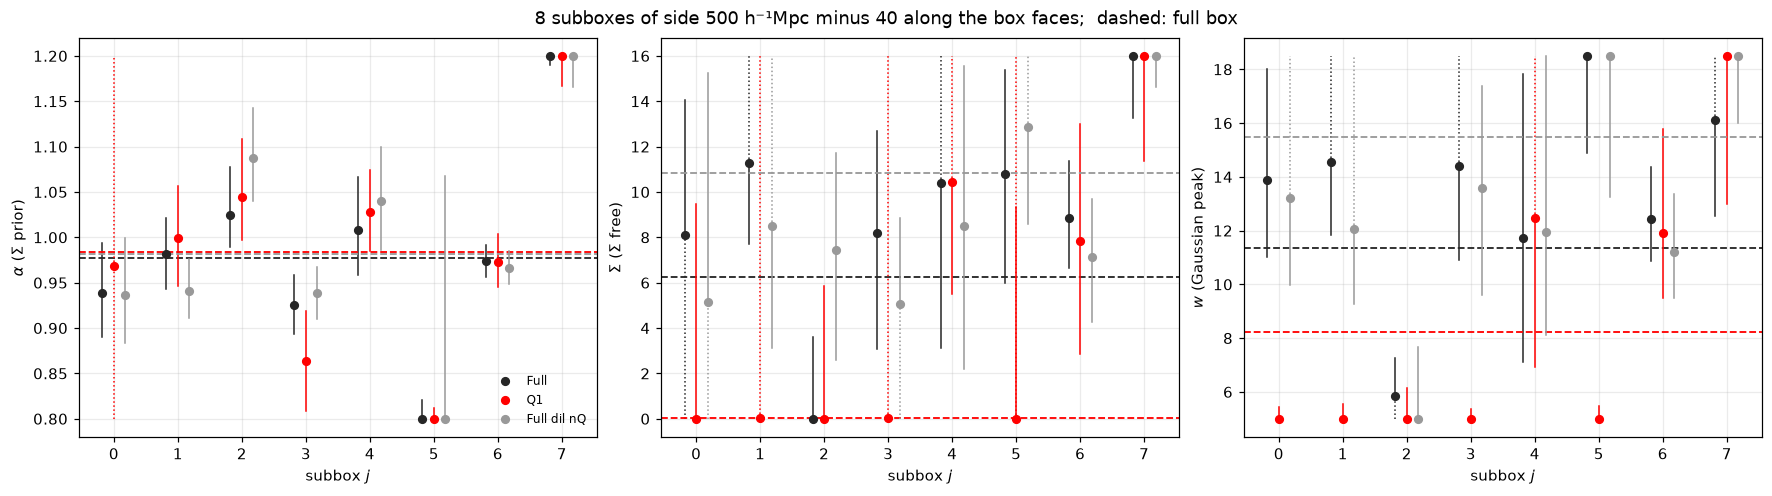

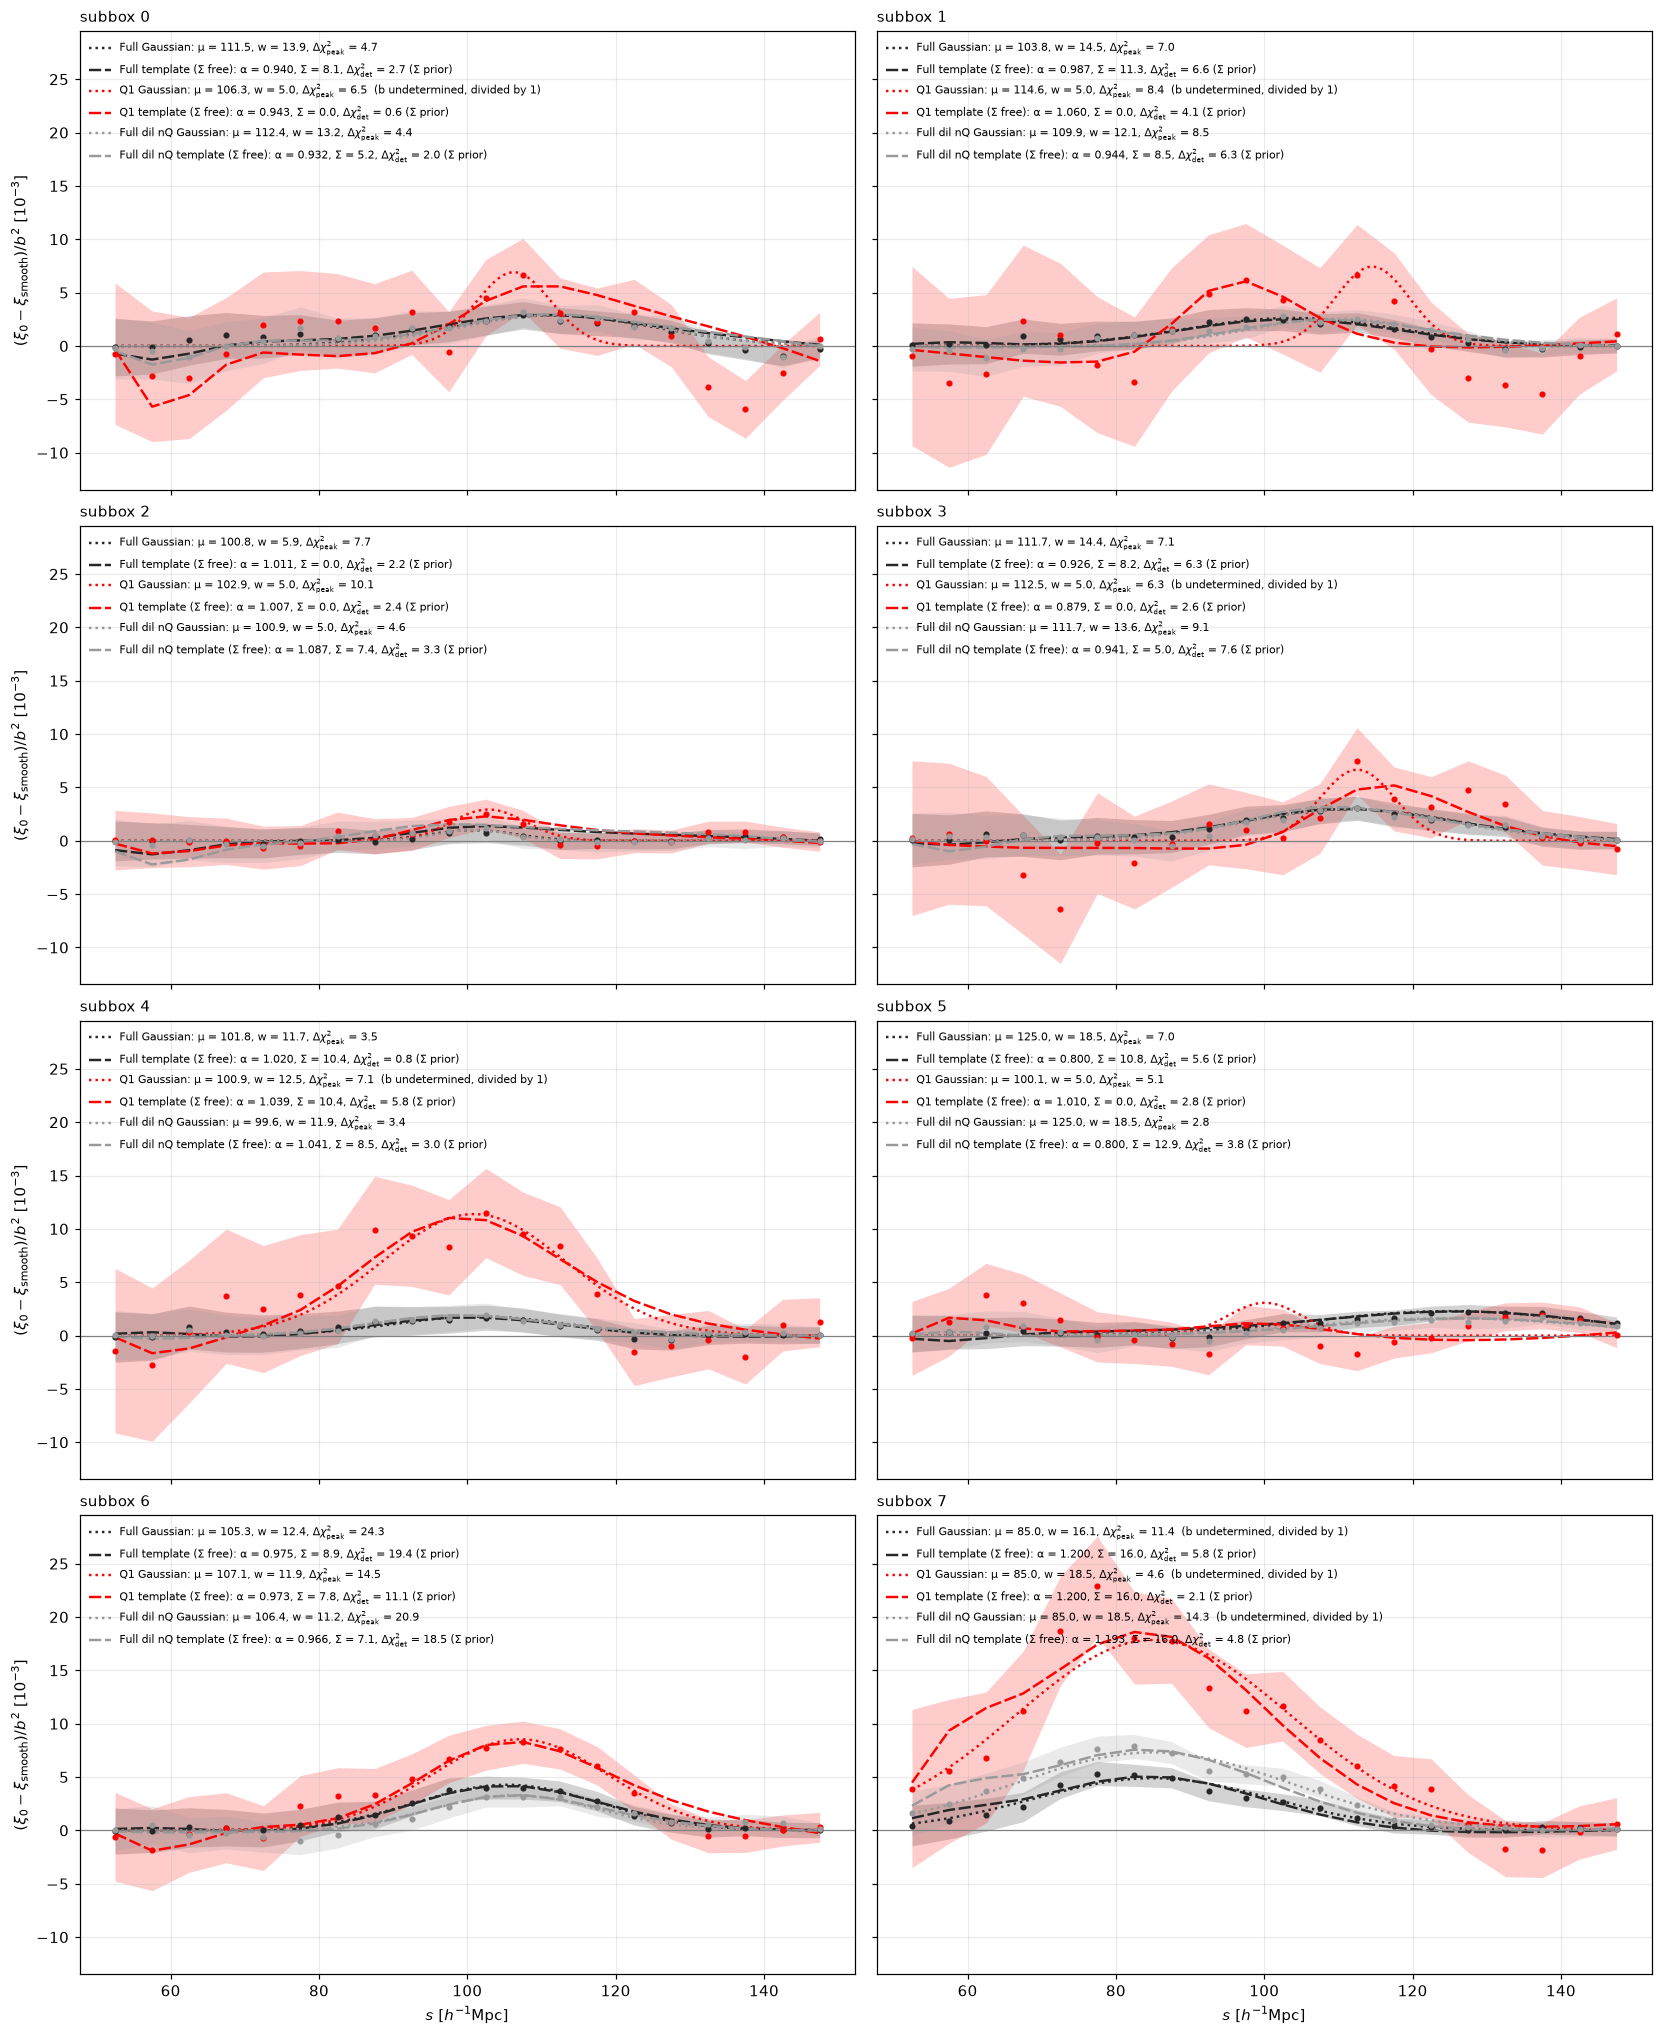

In [ ]:
offs = {lab: (i - (len(oct_samples) - 1) / 2) * 0.18 for i, lab in enumerate(oct_samples)}
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4), layout='constrained')
for a, key, lab_y in zip(ax, ('alpha', 'Sigma', 'w'), (r'$\alpha$ ($\Sigma$ prior)', r'$\Sigma$ ($\Sigma$ free)',
                                                      r'$w$ (Gaussian peak)')):
    for lab in oct_samples:
        c = SCOL.get(lab, 'k')
        for j in SUBS:
            r, x = R[lab, j], j + offs[lab]
            v, (lo, hi) = r[key], (r[k_] for k_ in IV[key])
            if not np.isfinite(v):
                continue
            for end, edge_ in ((lo, RANGE[key][0]), (hi, RANGE[key][1])):
                ok = np.isfinite(end)
                a.plot([x, x], sorted((v, end if ok else edge_)), color=c, lw=1, ls='-' if ok else ':')
            a.plot(x, v, 'o', color=c, ms=5, label=lab if j == 0 else None, zorder=3)
        a.axhline(R[lab, 'box'][key], color=c, lw=1.2, ls='--')
    a.set_xticks(SUBS); a.set_xlabel('subbox $j$'); a.set_ylabel(lab_y)
ax[0].legend(fontsize=8, frameon=False)
fig.suptitle(f'{n_sub} subboxes of side {L_sub:g} h⁻¹Mpc minus {face_guard:g} along the box faces;  dashed: full box')
save_show('2_per_subbox')

# as desilike_fits section 8(c): points at the bin centres with their 68% errors as a band; the Gaussian (dotted) and the
# template (dashed) at equal weight, each with its own detection
LW_FIT, LS_TEMPLATE, LS_GAUSS = 1.6, (0, (5, 1.5)), ':'
ncol = min(n_sub, 2); nrow = -(-n_sub // ncol)
fig, ax = plt.subplots(nrow, ncol, figsize=(7.5 * ncol, 4.6 * nrow), sharex=True, sharey=True, squeeze=False,
                       layout='constrained')
for j in SUBS:
    a = ax[j // ncol, j % ncol]
    for lab in oct_samples:
        d, r, c = D[lab, j], R[lab, j], SCOL.get(lab, 'k')
        if not np.isfinite(r['w']):
            continue
        s, b2 = s_c[m_fit], d['b']**2 if d['b_ok'] else 1.0       # no bias: divided by 1
        y, e = (d['xi'][m_fit] - r['smooth']) / b2 * 1e3, d['sig'][m_fit] / b2 * 1e3
        sf = np.linspace(s[0], s[-1], 400)
        a.fill_between(s, y - e, y + e, color=c, alpha=0.2, lw=0, zorder=1)
        a.plot(s, y, 'o', ms=3, color=c, zorder=3)
        a.plot(sf, r['h'] * np.exp(-0.5 * ((sf - r['mu']) / r['w'])**2) / b2 * 1e3, ls=LS_GAUSS, color=c, lw=LW_FIT,
               label=f"{lab} Gaussian: μ = {r['mu']:.1f}, w = {r['w']:.1f}, " + r"$\Delta\chi^2_{\rm peak}$"
                     + f" = {r['dchi2_peak']:.1f}" + ('' if d['b_ok'] else '  (b undetermined, divided by 1)'))
        a.plot(s, (r['model_S'] - r['smooth']) / b2 * 1e3, ls=LS_TEMPLATE, color=c, lw=LW_FIT, zorder=2,
               label=f"{lab} template (Σ free): α = {r['alpha_S']:.3f}, "
                     f"Σ = {r['Sigma']:.1f}, " + r"$\Delta\chi^2_{\rm det}$" + f" = {r['det']:.1f} (Σ prior)")
    a.axhline(0, color='0.5', lw=0.8); a.set_title(f'subbox {j}', fontsize=10, loc='left')
    a.legend(fontsize=7, frameon=False, loc='upper left')
for a in ax[-1]:
    a.set_xlabel(r'$s\ [h^{-1}{\rm Mpc}]$')
for a in ax[:, 0]:
    a.set_ylabel(r'$(\xi_0-\xi_{\rm smooth})/b^2\ [10^{-3}]$')
save_show('3_peaks_per_subbox')